# 1. Checking the number of images for each raw set

In [1]:
from pathlib import Path

In [2]:
from pathlib import Path

base_dir = Path("../data/raw/chest_xray")
valid_exts = {".jpg", ".jpeg", ".png"}

for split in ["train", "val", "test"]:
    split_dir = base_dir / split
    print(f"==={split.upper()} SET ===")
    total_split = 0
    
    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            num_images = sum(1 for f in class_dir.iterdir() if f.suffix.lower() in valid_exts)
            total_split += num_images
            print(f"  {class_dir.name:<10}: {num_images} images")
            
    print(f"  -> Total: {total_split} Image\n")

===TRAIN SET ===
  NORMAL    : 1341 images
  PNEUMONIA : 3875 images
  -> Total: 5216 Image

===VAL SET ===
  NORMAL    : 8 images
  PNEUMONIA : 8 images
  -> Total: 16 Image

===TEST SET ===
  NORMAL    : 234 images
  PNEUMONIA : 390 images
  -> Total: 624 Image



In [1]:
print('hello world')

hello world


In [3]:
from pathlib import Path
from PIL import Image
import pandas as pd

In [4]:
if Path('kaggle/input').exists():
    base_dỉr ='/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray'
else:
    project_root = Path.cwd().parent
    base_dir = project_root / 'data/raw/chest_xray'


# 2. Checking the distribution for each set

In [21]:
valid_exts =['.jpeg', '.png', '.jpg']
records = []
corrupted_files = []

for split in ['train','val', 'test']:
    split_dir = base_dir / split
    if not split_dir.exists():
        continue

    for class_dir in split_dir.iterdir():
        if not class_dir.exists():
            continue

        for img_path in class_dir.iterdir():
            if img_path.suffix.lower() not in valid_exts:
                continue

            try:
                with Image.open(img_path) as img:
                    width, height = img.size
                    mode = img.mode  # 'L' là ảnh xám 1 kênh, 'RGB' là ảnh màu 3 kênh
                    records.append({
                        "split": split,
                        "label": class_dir.name,
                        "width": width,
                        "height": height,
                        "aspect_ratio": round(width / height, 2),
                        "mode": mode,
                        "path": str(img_path)
                    })
                
            except Exception as e:
                corrupted_files.append((str(img_path), e))
                
                

In [ ]:
df_sizes = pd.DataFrame(records)


,split,label,width,height,aspect_ratio,mode,path
0,train,PNEUMONIA,1144,656,1.74,L,/home/hiughetlinux/hoc-software/Chest_Xray_Pre...
1,train,PNEUMONIA,968,832,1.16,L,/home/hiughetlinux/hoc-software/Chest_Xray_Pre...
2,train,PNEUMONIA,823,459,1.79,RGB,/home/hiughetlinux/hoc-software/Chest_Xray_Pre...
3,train,PNEUMONIA,1384,944,1.47,L,/home/hiughetlinux/hoc-software/Chest_Xray_Pre...
4,train,PNEUMONIA,1296,1000,1.30,L,/home/hiughetlinux/hoc-software/Chest_Xray_Pre...
...,...,...,...,...,...,...,...
5851,test,NORMAL,1784,1389,1.28,L,/home/hiughetlinux/hoc-software/Chest_Xray_Pre...
5852,test,NORMAL,1949,1632,1.19,L,/home/hiughetlinux/hoc-software/Chest_Xray_Pre...
5853,test,NORMAL,1744,1168,1.49,L,/home/hiughetlinux/hoc-software/Chest_Xray_Pre...
5854,test,NORMAL,1866,1311,1.42,L,/home/hiughetlinux/hoc-software/Chest_Xray_Pre...


In [9]:
df_sizes['label'].value_counts()

label
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Label Distribution in all 3 set')

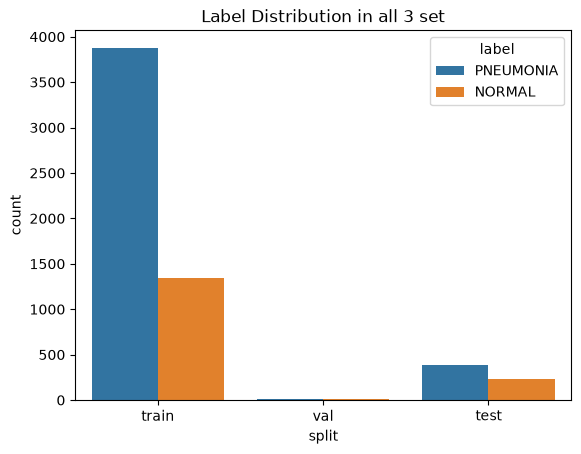

In [18]:
sns.countplot(data = df_sizes, x = 'split', hue = 'label')
plt.title('Label Distribution in all 3 set')

Text(0.5, 1.0, 'Mode Distribution in all 3 set')

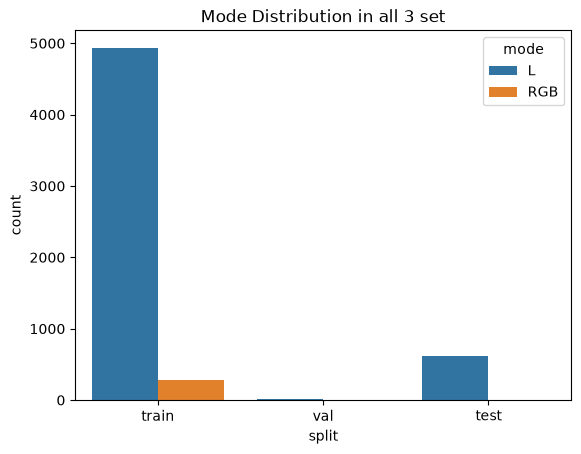

In [19]:
sns.countplot(data = df_sizes, x = 'split', hue = 'mode')
plt.title('Mode Distribution in all 3 set')

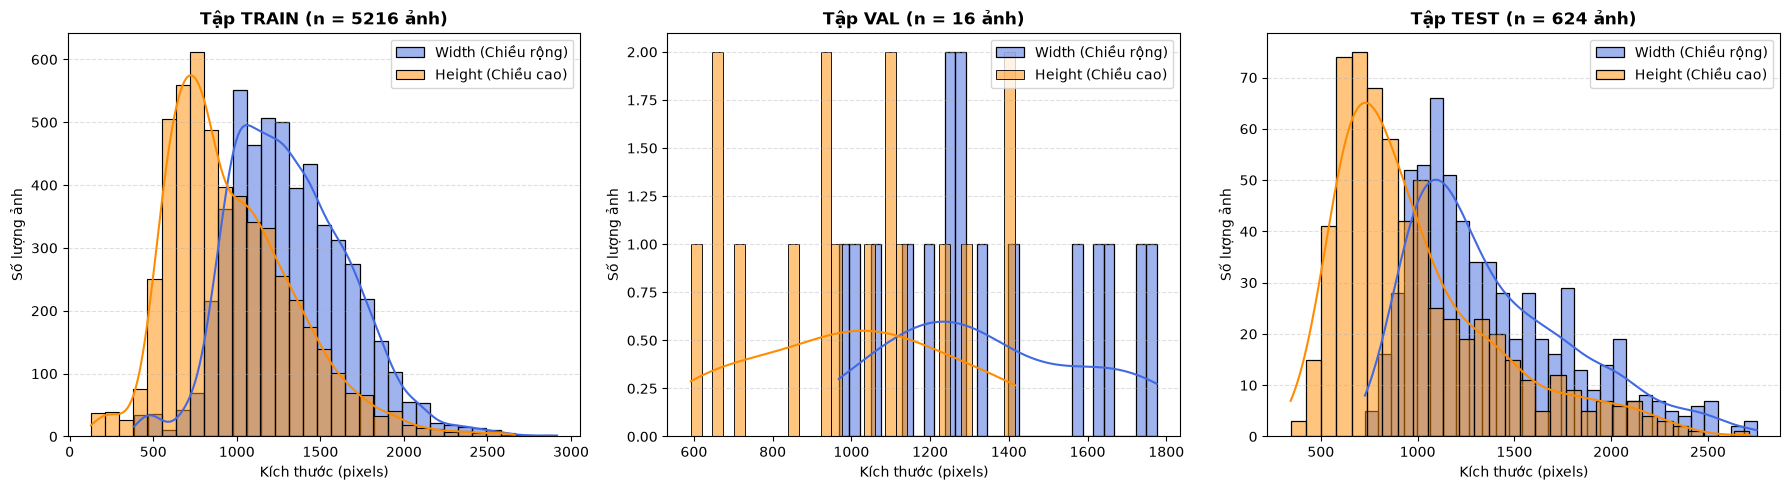

In [20]:

splits = ["train", "val", "test"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, split_name in zip(axes, splits):
    # Lọc dữ liệu riêng cho từng tập
    subset = df_sizes[df_sizes["split"] == split_name]
    
    # Vẽ phân bố chiều rộng (Width)
    sns.histplot(
        data=subset, 
        x="width", 
        bins=30, 
        color="royalblue", 
        alpha=0.5, 
        kde=True, 
        label="Width (Chiều rộng)", 
        ax=ax
    )
    
    # Vẽ phân bố chiều cao (Height) chồng lên cùng trục
    sns.histplot(
        data=subset, 
        x="height", 
        bins=30, 
        color="darkorange", 
        alpha=0.5, 
        kde=True, 
        label="Height (Chiều cao)", 
        ax=ax
    )
    
    ax.set_title(f"Tập {split_name.upper()} (n = {len(subset)} ảnh)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Kích thước (pixels)")
    ax.set_ylabel("Số lượng ảnh")
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
'''Ratio of Preumonia / Total'''
ratio = len(df_sizes[df_sizes['label']=='Pneu'])